# 04a — GeometryStore as GeoPandas

Load GeometryStore tables into GeoDataFrames. `plot_dayhike` draws one DayHike
LineString from ordered vertices.

**Here:** `vertices` and `amenities` as points; `dayhikes` and `ways` as lines;
`plot_dayhike` for a one-row `dayhikes` slice; leftover members (`in_chain`,
`unconnected_m`); way-tag counts and length-weighted trail character
(`way_frame`).

**Not here:** Catalog SQLite (`02_catalog.ipynb`), production ranking
(`03_ranking.ipynb`), FeatureVector experiments (`04_rank_feature_lab.ipynb`).

Open `data/catalog.sqlite` plus `data/catalog.geometry.sqlite` when both exist.
Otherwise build the committed fixture. Ranking does not read this file.


In [ ]:
import json
import os
import sqlite3
import tempfile
from pathlib import Path

import geopandas as gpd
import pandas as pd
from shapely.geometry import LineString

from dayhike import build_catalog, geometry_store_path_for

repo = Path.cwd().resolve()
for candidate in (repo, *repo.parents):
    fixture = candidate / "tests" / "fixtures" / "catalog.osm"
    if fixture.is_file():
        repo = candidate
        break
else:
    raise FileNotFoundError("tests/fixtures/catalog.osm")

local = repo / "data" / "catalog.sqlite"
local_geometry = geometry_store_path_for(local)
if (
    local.is_file()
    and local_geometry.is_file()
    and "PYTEST_CURRENT_TEST" not in os.environ
):
    geometry_path = local_geometry
else:
    catalog_path = Path(tempfile.mkdtemp()) / "catalog.sqlite"
    build_catalog(fixture, catalog_path)
    geometry_path = geometry_store_path_for(catalog_path)

geo = sqlite3.connect(geometry_path)
print("geometry_store", geometry_path)
print("tables")
for (name,) in geo.execute(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY 1"
):
    n = geo.execute(f'SELECT COUNT(*) FROM "{name}"').fetchone()[0]
    print(f"  {name}\t{n}")


geometry_store /Users/mislavjordanic/Documents/projects/personal_projects/outdoors_destinations/data/catalog.geometry.sqlite
tables
  amenities	6120185
  dayhikes	155844
  geometry_meta	1
  vertices	37686493
  ways	3765059


## Load

`geometry_meta` has no coordinates (pandas only). The other four tables become
GeoDataFrames in EPSG:4326.

| Frame | Geometry |
| --- | --- |
| `vertices` | Point per OSM node on a DayHike |
| `amenities` | Point per raw amenity (including Viewpoint, Peak, Shelter) |
| `dayhikes` | LineString from ordered vertices |
| `ways` | LineString per member way |


In [ ]:
geometry_meta = pd.read_sql_query("SELECT * FROM geometry_meta", geo)
dayhikes_tbl = pd.read_sql_query("SELECT * FROM dayhikes", geo)
vertices_tbl = pd.read_sql_query(
    "SELECT * FROM vertices ORDER BY dayhike_id, seq", geo
)
ways_tbl = pd.read_sql_query("SELECT * FROM ways ORDER BY dayhike_id, seq", geo)
amenities_tbl = pd.read_sql_query("SELECT * FROM amenities", geo)

vertices = gpd.GeoDataFrame(
    vertices_tbl,
    geometry=gpd.points_from_xy(vertices_tbl.longitude, vertices_tbl.latitude),
    crs="EPSG:4326",
)
amenities = gpd.GeoDataFrame(
    amenities_tbl,
    geometry=gpd.points_from_xy(amenities_tbl.longitude, amenities_tbl.latitude),
    crs="EPSG:4326",
)

line_rows = []
for dayhike_id, grp in vertices_tbl.groupby("dayhike_id", sort=True):
    coords = list(zip(grp.longitude.to_numpy(), grp.latitude.to_numpy()))
    line_rows.append(
        {
            "id": int(dayhike_id),
            "geometry": LineString(coords) if len(coords) >= 2 else None,
        }
    )
dayhikes = gpd.GeoDataFrame(
    dayhikes_tbl.merge(pd.DataFrame(line_rows), on="id"),
    geometry="geometry",
    crs="EPSG:4326",
)

node_xy = (
    vertices_tbl.drop_duplicates("node_id").set_index("node_id")[
        ["longitude", "latitude"]
    ]
)


def way_line(node_ids_json: str) -> LineString | None:
    coords = []
    for node_id in json.loads(node_ids_json):
        if node_id not in node_xy.index:
            continue
        lon, lat = node_xy.loc[node_id]
        coords.append((float(lon), float(lat)))
    if len(coords) < 2:
        return None
    return LineString(coords)


ways = gpd.GeoDataFrame(
    ways_tbl,
    geometry=ways_tbl["node_ids"].map(way_line),
    crs="EPSG:4326",
)

geo.close()

for name, frame in (
    ("geometry_meta", geometry_meta),
    ("vertices", vertices),
    ("amenities", amenities),
    ("dayhikes", dayhikes),
    ("ways", ways),
):
    geom = getattr(frame, "geometry", None)
    extra = ""
    if geom is not None:
        extra = f"\tcrs={frame.crs}\tempty_geom={int(geom.isna().sum())}"
    print(f"geopandas {name}\t{frame.shape}{extra}")


geopandas geometry_meta	(1, 2)
geopandas vertices	(37686493, 7)	crs=EPSG:4326	empty_geom=0
geopandas amenities	(6120185, 6)	crs=EPSG:4326	empty_geom=0
geopandas dayhikes	(155844, 9)	crs=EPSG:4326	empty_geom=0
geopandas ways	(3765059, 7)	crs=EPSG:4326	empty_geom=671309


The four spatial frames are in the kernel now: `vertices`, `amenities`,
`dayhikes`, `ways`. `geometry_meta` is attribution only.


In [ ]:
print("vertices")
print(vertices.head().to_string())
print("amenities kinds", amenities["kind"].value_counts().to_dict() if len(amenities) else {})
print("dayhikes")
hike_cols = [c for c in ("id", "name", "name_origin", "length_m", "unconnected_m") if c in dayhikes.columns]
print(dayhikes[hike_cols].to_string())
print("ways", len(ways), "member ways")
if "in_chain" in ways.columns:
    print("ways in_chain", ways["in_chain"].value_counts().to_dict())

if "PYTEST_CURRENT_TEST" in os.environ:
    import matplotlib as mpl

    mpl.use("Agg")
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))
if not dayhikes.empty:
    dayhikes.plot(ax=ax, color="#2a6", linewidth=2)
if not amenities.empty:
    amenities.plot(ax=ax, column="kind", markersize=20, legend=True)
ax.set_title("dayhikes + amenities")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
fig.tight_layout()
try:
    from IPython.display import display

    display(fig)
except ImportError:
    pass
plt.close(fig)


In [ ]:
import math

from dayhike.catalog import EARTH_RADIUS_M

ends = (
    vertices.sort_values(["dayhike_id", "seq"])
    .groupby("dayhike_id")
    .agg(
        lat1=("latitude", "first"),
        lon1=("longitude", "first"),
        lat2=("latitude", "last"),
        lon2=("longitude", "last"),
    )
)


def haversine_m(lat1, lon1, lat2, lon2):
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    return 2 * EARTH_RADIUS_M * math.asin(math.sqrt(a))


ends["start_end_m"] = [
    haversine_m(lat1, lon1, lat2, lon2)
    for lat1, lon1, lat2, lon2 in ends[["lat1", "lon1", "lat2", "lon2"]].itertuples(
        index=False
    )
]
dayhikes["start_end_m"] = dayhikes["id"].map(ends["start_end_m"])
print(dayhikes["start_end_m"].describe().to_string())
print("closed_lt_50m", int((dayhikes["start_end_m"] < 50).sum()))
dayhikes.sort_values("start_end_m")[["id", "name", "length_m", "start_end_m"]]

count    155844.000000
mean       2096.336075
std        2469.085674
min           0.000000
25%         563.249701
50%        1342.609902
75%        2621.792940
max       18313.047848
closed_lt_50m 31133


,id,name,length_m,start_end_m
77921,11286263,Преконошка пећина,4324.057989,0.000000
75005,10982594,Kranich-Rundwanderweg 5,10997.035219,0.000000
75007,10982790,Oranges Buchenblatt,10154.108549,0.000000
20592,2722823,"Kaufungen, O4 - Fachwerkweg Oberkaufungen",1384.805344,0.000000
75013,10983312,Chemin des Poissoniers,7302.218263,0.000000
...,...,...,...,...
25202,3247849,HAR127,19370.498584,17744.763676
36513,5254921,LU-5513-c,19559.655897,17818.029402
141555,19146369,Södra Kungsleden - Stage 18,19546.200222,18197.584853
141269,19093554,Lapplandsleden - Stage 2,19856.018401,18237.851148


## Plot one DayHike

Pass a one-row `dayhikes` slice to `plot_dayhike`. The line is the assembled
vertex chain; red dots are those nodes; larger markers are the first and last
vertex.

`plot_dayhike_progress` keeps those start/end markers and colors the nodes in
between by position along the DayHike (start of colormap → end of colormap).

     id                       name     length_m  unconnected_m
0  2381  Moorwanderweg Tanner Moor  4147.776497     110.603271


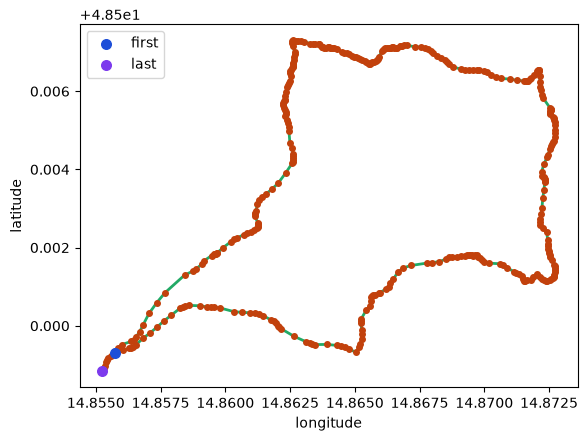

In [ ]:
def plot_dayhike(hike):
    fig, ax = plt.subplots(figsize=(6, 6))
    if hike.geometry.notna().any():
        hike.plot(ax=ax, color="#2a6", linewidth=2)
        for geom in hike.geometry.dropna():
            xs, ys = zip(*geom.coords)
            ax.scatter(xs, ys, s=16, color="#c2410c", zorder=3)
            ax.scatter(
                [xs[0]], [ys[0]], s=48, color="#1d4ed8", zorder=4, label="first"
            )
            ax.scatter(
                [xs[-1]], [ys[-1]], s=48, color="#7c3aed", zorder=5, label="last"
            )
        ax.legend()
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    fig.tight_layout()
    try:
        from IPython.display import display

        display(fig)
    except ImportError:
        pass
    plt.close(fig)


one = dayhikes.iloc[[0]]
print(one[[c for c in ("id", "name", "length_m", "unconnected_m") if c in one.columns]].to_string())
plot_dayhike(one)

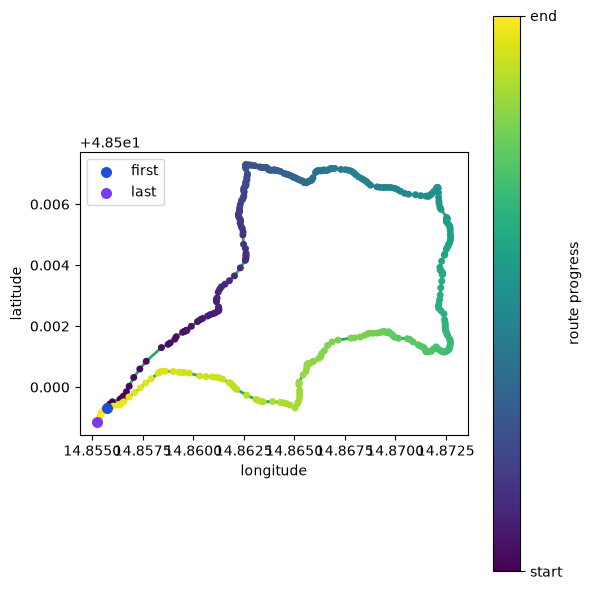

In [ ]:
def plot_dayhike_progress(hike):
    fig, ax = plt.subplots(figsize=(6, 6))
    if hike.geometry.notna().any():
        hike.plot(ax=ax, color="#2a6", linewidth=2)
        progress_shown = False
        for geom in hike.geometry.dropna():
            coords = list(geom.coords)
            n = len(coords)
            if n > 2:
                xs, ys = zip(*coords[1:-1])
                t = [i / (n - 1) for i in range(1, n - 1)]
                sc = ax.scatter(
                    xs,
                    ys,
                    c=t,
                    cmap="viridis",
                    vmin=0,
                    vmax=1,
                    s=16,
                    zorder=3,
                )
                if not progress_shown:
                    cbar = fig.colorbar(sc, ax=ax)
                    cbar.set_label("route progress")
                    cbar.set_ticks([0, 1])
                    cbar.set_ticklabels(["start", "end"])
                    progress_shown = True
            ax.scatter(
                [coords[0][0]], [coords[0][1]], s=48, color="#1d4ed8", zorder=5,
                label="first",
            )
            ax.scatter(
                [coords[-1][0]], [coords[-1][1]], s=48, color="#7c3aed", zorder=5,
                label="last",
            )
        ax.legend()
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    fig.tight_layout()
    try:
        from IPython.display import display

        display(fig)
    except ImportError:
        pass
    plt.close(fig)


plot_dayhike_progress(one)

## Leftover member ways

OSM member order is not a guaranteed walk. Ingest glues a way only when it shares
an endpoint with the current chain; later members are still tried. Skipped ways
stay in `ways` with `in_chain = 0`. Their real length is `unconnected_m`.
Catalog `length_m` and the DayHike LineString follow the chain only — no jump
through empty space.

Prefer id 2381 when present (Moorwanderweg Tanner Moor: a short extra after a
near-loop). Otherwise the first DayHike with `unconnected_m > 0` (the fixture's
Ridge Walk). Leftover-way nodes that never appear on the chain are not in
`vertices`, so those extras may have empty geometry here. Interior attach and
dominant-cycle extract are later work (ADR-0009).

An older GeometryStore without these columns needs a re-ingest.

  id                      name    length_m  unconnected_m
2381 Moorwanderweg Tanner Moor 4147.776497     110.603271
member ways
 seq    way_id  in_chain
   0   9351841         1
   1 219394209         1
   2 219394213         1
   3 219394211         1
   4 847339137         1
   5 847339136         1
   6 847339135         1
   7 847339134         1
   8 219394203         1
   9 847339133         1
  10 847339131         1
  11  43121415         1
  12 737612380         1
  13 847734862         1
  14 847734861         1
  15  43121416         1
  16   9351839         1
  17  43121417         0
skipped 1 empty_geom 1


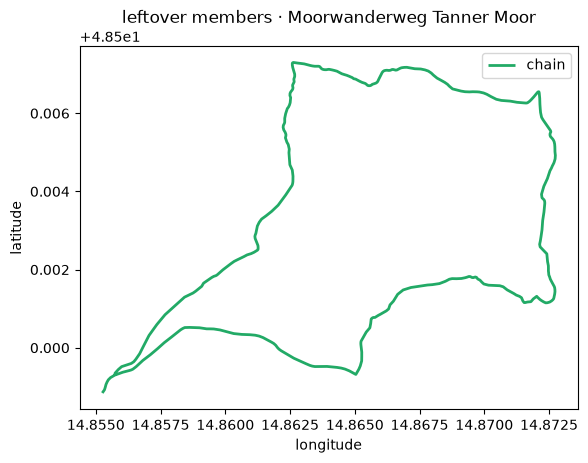

In [ ]:
if "unconnected_m" not in dayhikes.columns or "in_chain" not in ways.columns:
    print("leftover_ways\tskip_re_ingest")
else:
    leftover = dayhikes[dayhikes["unconnected_m"] > 0].copy()
    if 2381 in set(dayhikes["id"]):
        demo = dayhikes[dayhikes["id"] == 2381]
    elif not leftover.empty:
        demo = leftover.iloc[[0]]
    else:
        demo = dayhikes.iloc[[0]]
    demo_id = int(demo["id"].iloc[0])
    demo_ways = ways[ways["dayhike_id"] == demo_id]
    skipped = demo_ways[demo_ways["in_chain"] == 0]
    print(
        demo[
            [c for c in ("id", "name", "length_m", "unconnected_m") if c in demo.columns]
        ].to_string(index=False)
    )
    print("member ways")
    print(demo_ways[["seq", "way_id", "in_chain"]].to_string(index=False))
    print("skipped", len(skipped), "empty_geom", int(skipped.geometry.isna().sum()))

    fig, ax = plt.subplots(figsize=(6, 6))
    if demo.geometry.notna().any():
        demo.plot(ax=ax, color="#2a6", linewidth=2, label="chain")
    if not skipped.empty and skipped.geometry.notna().any():
        skipped.plot(ax=ax, color="#c2410c", linewidth=2, label="leftover")
    ax.legend()
    ax.set_title(f"leftover members · {demo['name'].iloc[0]}")
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    fig.tight_layout()
    try:
        from IPython.display import display

        display(fig)
    except ImportError:
        pass
    plt.close(fig)

## Way tags on the walked line

`ways.tags` is the OSM tag bag on each member way. `vertices` has no tag bag: ingest keeps coordinates and `ele` only, and `sample-dem` may overwrite `ele` from FABDEM. There is no node-tag vocabulary to count.

The charts count each walked OSM way once (`in_chain = 1`). Leftover members stay out. `way_frame` is one row per DayHike, and a way that several hikes share is measured on each of them. This notebook does not rank and does not write the Catalog. `difficulty_ordinal` in the Catalog stays the strictest `sac_scale` and is not repeated here.

A dummy column per tag is the wrong encoding. A full extract has thousands of keys. Most are names, refs, and provenance (`source`, `wikidata`, `name:*`) or urban-road furniture (`lanes`, `maxspeed`, `sidewalk`). A mention count also grows with how finely the route was split into ways, so it repeats `length_m`. A missing `surface` is not "not asphalt".

Each share is metres of that class divided by metres of the walked line. Length is the haversine along the way's nodes, using coordinates from `vertices`. A node missing from `vertices` is skipped. On a full GeometryStore the next cell indexes every trail node (about 1.5 GB) and takes a few minutes, then releases that index.

Missing versus zero:

- `highway` is present on essentially every way, so `trail_share` and `road_share` are real fractions. Zero means none of the walked length is that class.
- `bridge`, `ford`, `tunnel`, `handrail`, `safety_rope`, `steps` (`highway=steps`), and `via_ferrata` (`highway=via_ferrata`) are affirmative. An absent tag counts as zero metres. `via_ferrata_share` stays a length fraction so a few rungs and a route that is entirely a via ferrata do not look the same.
- `surface`, `smoothness`, `trail_visibility`, and `tracktype` are often absent. Bucket shares and ordinals are NaN when none of the walked length carries a usable value. `surface_tagged_share` is the fraction that has any `surface` tag, and zero there is a real observation.
- If a column is later scaled for ranking, NaN becomes the mean of the hikes that have a value. An untagged hike would not look like the worst grade or like a zero share. Comparing neighbor order belongs in `04_rank_feature_lab.ipynb`.

Surface uses the first `;`-separated token, lowercased:

| Bucket | Tokens |
| --- | --- |
| paved | asphalt, paving_stones, concrete, concrete:plates, sett, cobblestone, unhewn_cobblestone, paved, chipseal, metal |
| firm | gravel, compacted, fine_gravel, pebblestone, wood |
| soft | ground, dirt, grass, unpaved, earth, sand, mud, clay |
| rock | rock, stone, scree, bare_rock |

Any other surface token still counts in `surface_tagged_share` and in none of the four buckets, so those four shares can sum to less than 1. They are fractions of tagged length, not of the whole hike.

Trail highways: `path`, `footway`, `track`, `bridleway`, `steps`, `via_ferrata`, `ladder`. Road highways: `residential`, `unclassified`, `tertiary`, `secondary`, `primary`, `trunk`, `motorway`, their `_link` forms, `service`, `living_street`, `road`. `cycleway`, `pedestrian`, and `construction` are neither share, so the two shares do not have to sum to 1. `steps_share` is the staircase part of `trail_share`.

Ordinals are a length-weighted mean on the tagged metres only. Values outside these lists are ignored, the same way an unrecognized `sac_scale` is ignored when Difficulty is built:

| Column | Values |
| --- | --- |
| `smoothness_ordinal` | excellent 0, good 1, intermediate 2, bad 3, very_bad 4, horrible 5, very_horrible 6, impassable 7 |
| `trail_visibility_ordinal` | excellent 0, good 1, intermediate 2, bad 3, horrible 4, no 5 |
| `tracktype_ordinal` | grade1 1 … grade5 5 |

Relation `description` is not embedded. ADR-0003 rejected embeddings of text built from the same tags. `docs/future-work.md` allows showing OSM `description`, not treating it as a review.


ways_in_chain
  in_chain=0	889185
  in_chain=1	2875874
vertex_ele
  has_ele=0	26616
  has_ele=1	37659877
indexing vertices
vertex_nodes	30858290
scanning in_chain ways
scan_seconds	93.2	unique_in_chain_ways	2246128	with_length	2875874	without_length	0
distinct_keys	4050
key_bands {10000: 58, 1000: 215, 100: 594, 10: 1651, 1: 4050}
way_tag_keys
  2245031	highway
  1311175	surface
  798610	name
  607085	tracktype
  315339	maxspeed
  270930	lit
  260640	bicycle
  249291	foot
  242288	source
  239326	smoothness
  224583	sac_scale
  170904	width
  163008	ref
  139166	mtb:scale
  132300	motor_vehicle
  125632	lanes
  123330	sidewalk
  121487	trail_visibility
  112138	layer
  109453	bridge
  104924	oneway
  103979	lane_markings
  93523	cycleway:both
  91537	incline
  78917	horse
way_tag_values
  highway	2245031	track=692096, path=498586, residential=284691, unclassified=226607, footway=134082, tertiary=123042, service=102597, secondary=60734
  surface	1311175	asphalt=553419, ground=152896, gr

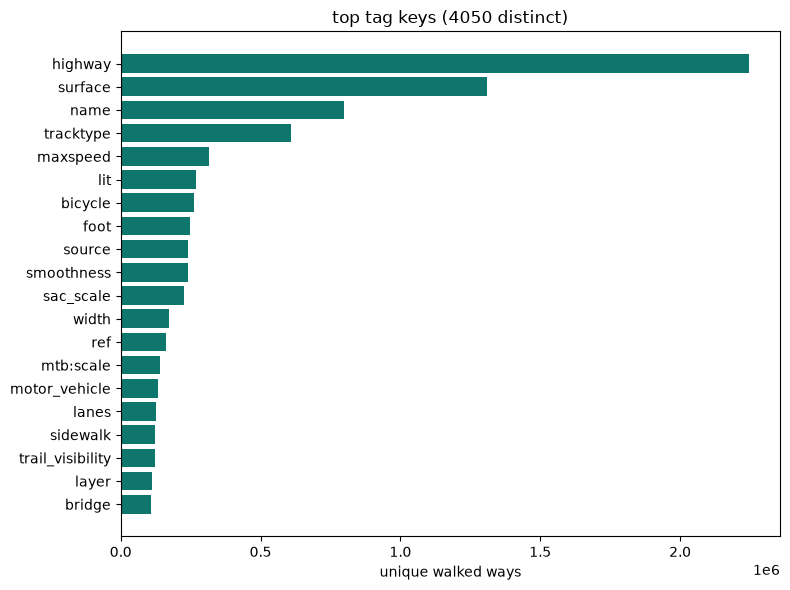

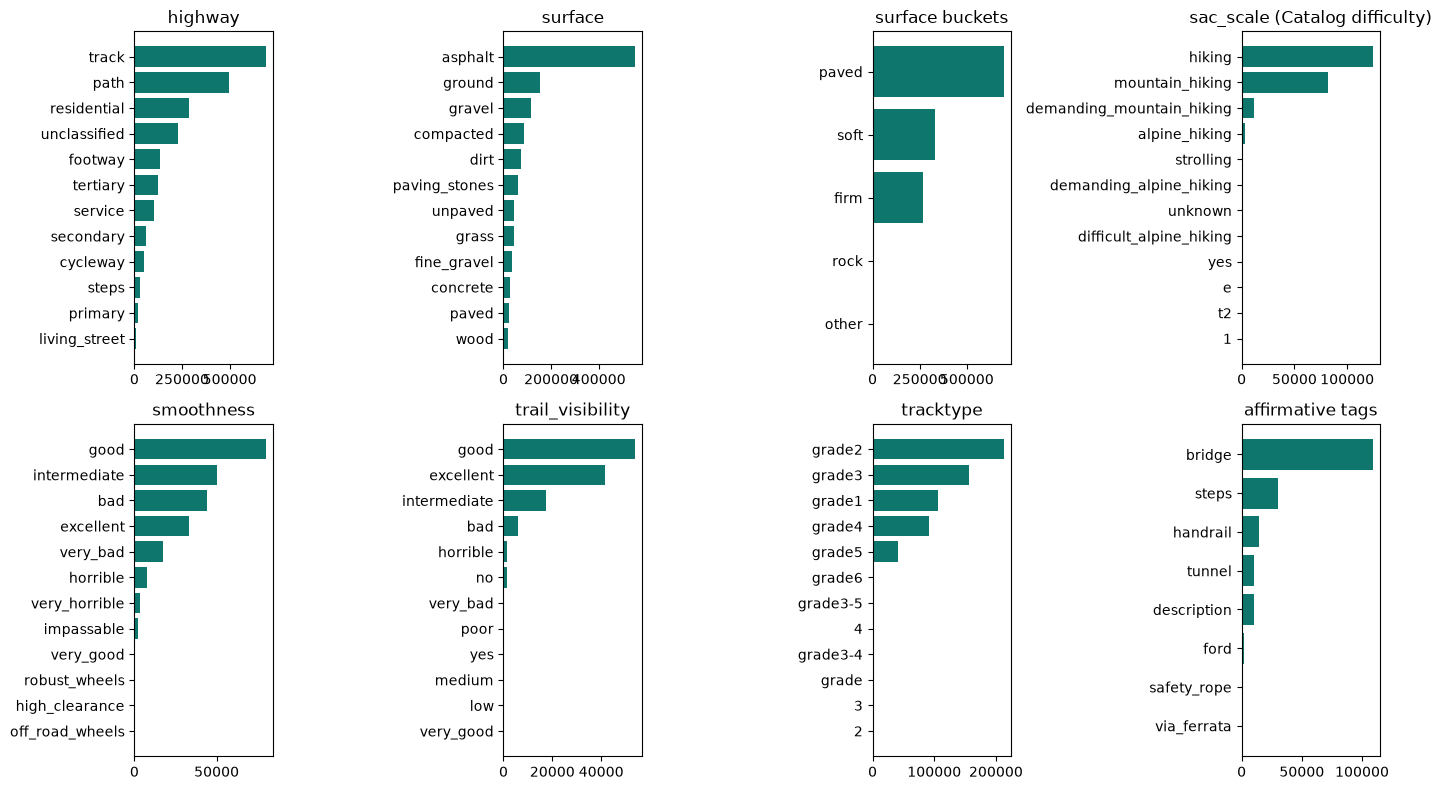

                           missing      zero       std  min       max
trail_share               0.000000  0.045918  0.292775  0.0  1.000000
road_share                0.000000  0.297509  0.274962  0.0  1.000000
surface_tagged_share      0.000000  0.151478  0.382379  0.0  1.000000
surface_paved_share       0.151478  0.228555  0.381652  0.0  1.000000
surface_firm_share        0.151478  0.362921  0.329277  0.0  1.000000
surface_soft_share        0.151478  0.305549  0.377618  0.0  1.000000
surface_rock_share        0.151478  0.823728  0.065786  0.0  1.000000
bridge_share              0.000000  0.629636  0.021003  0.0  1.000000
ford_share                0.000000  0.991293  0.010186  0.0  1.000000
tunnel_share              0.000000  0.944175  0.006669  0.0  0.875167
steps_share               0.000000  0.892187  0.014651  0.0  1.000000
handrail_share            0.000000  0.961635  0.006651  0.0  1.000000
safety_rope_share         0.000000  0.995528  0.009350  0.0  1.000000
via_ferrata_share   

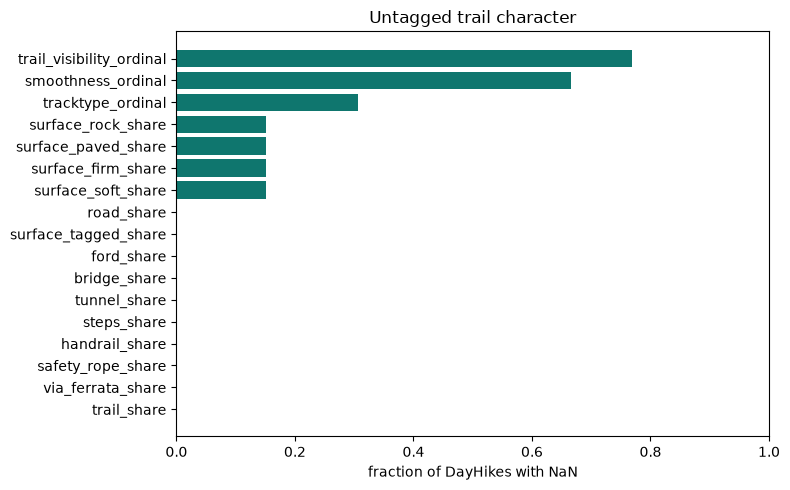

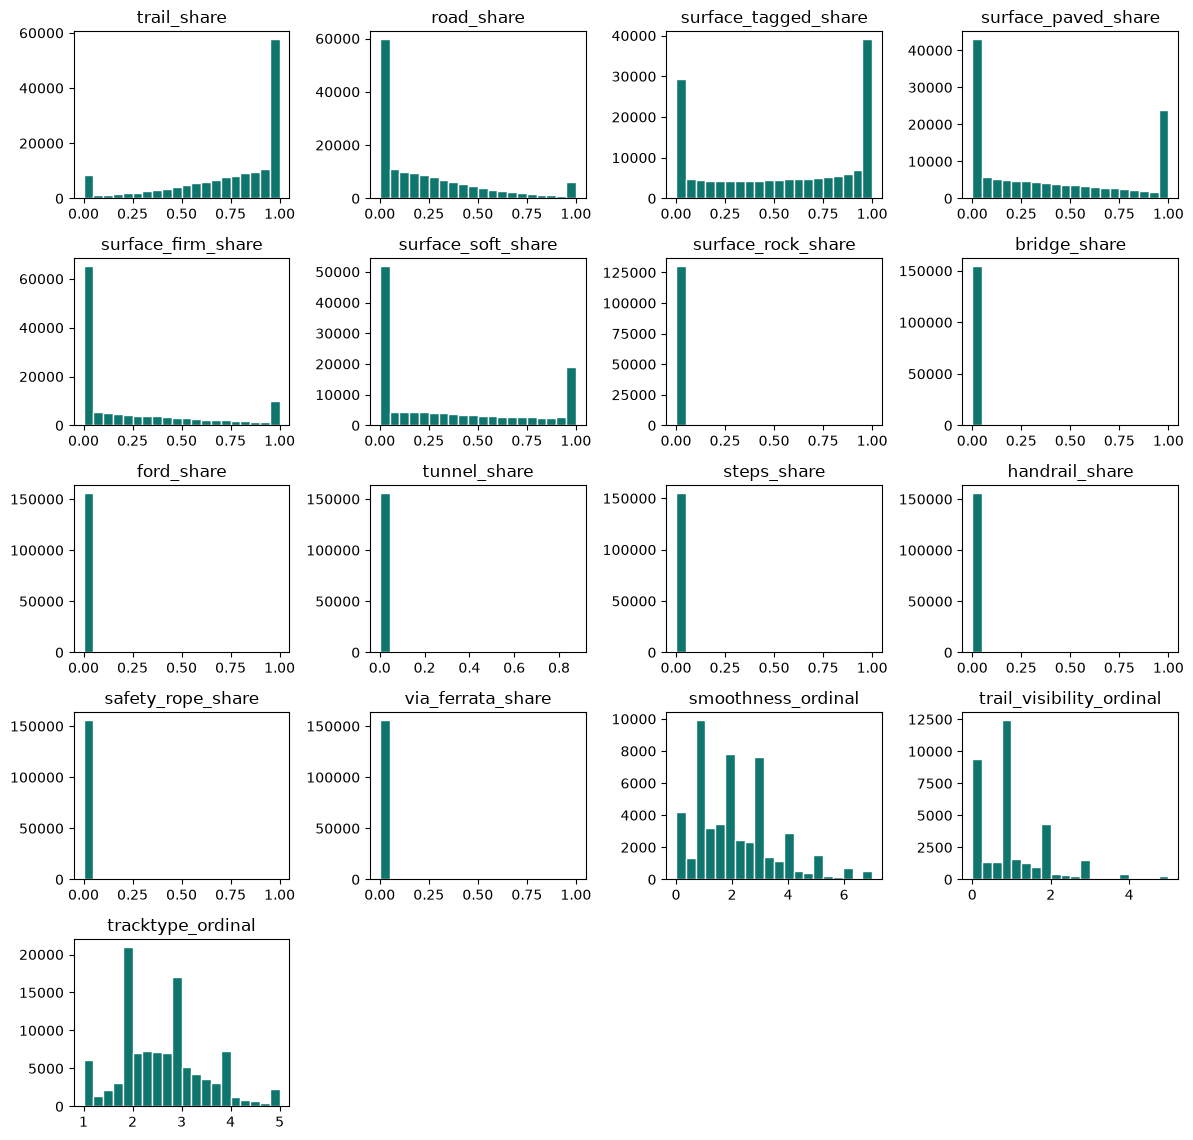

In [ ]:
import time
from collections import Counter

import numpy as np

TRAIL_HIGHWAY = frozenset(
    {"path", "footway", "track", "bridleway", "steps", "via_ferrata", "ladder"}
)
ROAD_HIGHWAY = frozenset(
    {
        "residential",
        "unclassified",
        "tertiary",
        "tertiary_link",
        "secondary",
        "secondary_link",
        "primary",
        "primary_link",
        "trunk",
        "trunk_link",
        "motorway",
        "motorway_link",
        "service",
        "living_street",
        "road",
    }
)
SURFACE_BUCKET = {}
for _token in (
    "asphalt",
    "paving_stones",
    "concrete",
    "concrete:plates",
    "sett",
    "cobblestone",
    "unhewn_cobblestone",
    "paved",
    "chipseal",
    "metal",
):
    SURFACE_BUCKET[_token] = "paved"
for _token in ("gravel", "compacted", "fine_gravel", "pebblestone", "wood"):
    SURFACE_BUCKET[_token] = "firm"
for _token in ("ground", "dirt", "grass", "unpaved", "earth", "sand", "mud", "clay"):
    SURFACE_BUCKET[_token] = "soft"
for _token in ("rock", "stone", "scree", "bare_rock"):
    SURFACE_BUCKET[_token] = "rock"
SMOOTHNESS_RANK = {
    "excellent": 0,
    "good": 1,
    "intermediate": 2,
    "bad": 3,
    "very_bad": 4,
    "horrible": 5,
    "very_horrible": 6,
    "impassable": 7,
}
VISIBILITY_RANK = {
    "excellent": 0,
    "good": 1,
    "intermediate": 2,
    "bad": 3,
    "horrible": 4,
    "no": 5,
}
TRACKTYPE_RANK = {f"grade{grade}": grade for grade in range(1, 6)}
ABSENT = frozenset({"no", "abandoned", "razed"})
SURFACE_NAMES = ("paved", "firm", "soft", "rock")
FLAG_NAMES = (
    "bridge",
    "ford",
    "tunnel",
    "steps",
    "handrail",
    "safety_rope",
    "via_ferrata",
)
ORDINAL_RANK = {
    "smoothness": SMOOTHNESS_RANK,
    "trail_visibility": VISIBILITY_RANK,
    "tracktype": TRACKTYPE_RANK,
}
VALUE_KEYS = (
    "highway",
    "surface",
    "sac_scale",
    "smoothness",
    "trail_visibility",
    "tracktype",
    "bridge",
    "tunnel",
    "ford",
    "handrail",
    "safety_rope",
)
WAY_FEATURE_NAMES = (
    "trail_share",
    "road_share",
    "surface_tagged_share",
    "surface_paved_share",
    "surface_firm_share",
    "surface_soft_share",
    "surface_rock_share",
    "bridge_share",
    "ford_share",
    "tunnel_share",
    "steps_share",
    "handrail_share",
    "safety_rope_share",
    "via_ferrata_share",
    "smoothness_ordinal",
    "trail_visibility_ordinal",
    "tracktype_ordinal",
)


def first_token(raw):
    if not raw:
        return None
    token = raw.split(";", 1)[0].strip().lower()
    return token or None


def show_fig(fig):
    try:
        from IPython.display import display

        display(fig)
    except ImportError:
        pass
    plt.close(fig)


def barh_counter(ax, counter, title, limit=12):
    items = counter.most_common(limit)
    if not items:
        ax.set_title(f"{title} (none)")
        ax.tick_params(left=False, labelleft=False)
        return
    labels, counts = zip(*reversed(items))
    ax.barh(list(labels), list(counts), color="#0f766e")
    ax.set_title(title)


tag_geo = sqlite3.connect(geometry_path)
way_columns_present = {
    row[1] for row in tag_geo.execute("PRAGMA table_info(ways)")
}
if not {"in_chain", "tags", "node_ids"} <= way_columns_present:
    tag_geo.close()
    print("way_tags\tskip_re_ingest")
else:
    print("ways_in_chain", flush=True)
    for flag, count in tag_geo.execute("SELECT in_chain, COUNT(*) FROM ways GROUP BY 1"):
        print(f"  in_chain={flag}\t{count}")
    print("vertex_ele", flush=True)
    for has_ele, count in tag_geo.execute(
        "SELECT ele IS NOT NULL, COUNT(*) FROM vertices GROUP BY 1"
    ):
        print(f"  has_ele={has_ele}\t{count}")

    started = time.perf_counter()
    print("indexing vertices", flush=True)
    node_xy = {}
    vertex_cursor = tag_geo.execute(
        "SELECT node_id, latitude, longitude FROM vertices"
    )
    while True:
        batch = vertex_cursor.fetchmany(200_000)
        if not batch:
            break
        for node_id, lat, lon in batch:
            if node_id not in node_xy:
                node_xy[node_id] = (lat, lon)
    print(f"vertex_nodes\t{len(node_xy)}", flush=True)

    ids = [int(hike_id) for hike_id in dayhikes["id"].tolist()]
    index_of = {hike_id: i for i, hike_id in enumerate(ids)}
    n_hikes = len(ids)
    total_m = np.zeros(n_hikes)
    trail_m = np.zeros(n_hikes)
    road_m = np.zeros(n_hikes)
    surf_m = {name: np.zeros(n_hikes) for name in SURFACE_NAMES}
    surf_tagged_m = np.zeros(n_hikes)
    flag_m = {name: np.zeros(n_hikes) for name in FLAG_NAMES}
    ordinal_sum = {name: np.zeros(n_hikes) for name in ORDINAL_RANK}
    ordinal_m = {name: np.zeros(n_hikes) for name in ORDINAL_RANK}
    length_cache = {}
    seen_ways = set()
    key_counts = Counter()
    value_counts = {key: Counter() for key in VALUE_KEYS}
    ways_with_length = 0
    ways_without_length = 0

    def way_length_m(node_ids):
        coords = []
        for node_id in node_ids:
            point = node_xy.get(node_id)
            if point is None or (coords and coords[-1] == point):
                continue
            coords.append(point)
        return sum(
            haversine_m(start[0], start[1], end[0], end[1])
            for start, end in zip(coords, coords[1:])
        )

    print("scanning in_chain ways", flush=True)
    way_cursor = tag_geo.execute(
        "SELECT dayhike_id, way_id, node_ids, tags FROM ways WHERE in_chain = 1"
    )
    while True:
        batch = way_cursor.fetchmany(50_000)
        if not batch:
            break
        for dayhike_id, way_id, node_ids_json, tags_json in batch:
            hike_index = index_of.get(dayhike_id)
            if hike_index is None:
                continue
            tags = json.loads(tags_json)
            length = length_cache.get(way_id)
            if length is None:
                length = way_length_m(json.loads(node_ids_json))
                length_cache[way_id] = length
            if way_id not in seen_ways:
                seen_ways.add(way_id)
                for key in tags:
                    key_counts[key] += 1
                for key, counter in value_counts.items():
                    token = first_token(tags.get(key))
                    if token is not None:
                        counter[token] += 1
            if length <= 0:
                ways_without_length += 1
                continue
            ways_with_length += 1
            total_m[hike_index] += length
            highway = first_token(tags.get("highway"))
            if highway in TRAIL_HIGHWAY:
                trail_m[hike_index] += length
            elif highway in ROAD_HIGHWAY:
                road_m[hike_index] += length
            if highway == "steps":
                flag_m["steps"][hike_index] += length
            if highway == "via_ferrata":
                flag_m["via_ferrata"][hike_index] += length
            for key in ("bridge", "ford", "tunnel", "handrail", "safety_rope"):
                token = first_token(tags.get(key))
                if token is not None and token not in ABSENT:
                    flag_m[key][hike_index] += length
            surface = first_token(tags.get("surface"))
            if surface is not None:
                surf_tagged_m[hike_index] += length
                bucket = SURFACE_BUCKET.get(surface)
                if bucket is not None:
                    surf_m[bucket][hike_index] += length
            for name, ranks in ORDINAL_RANK.items():
                rank = ranks.get(first_token(tags.get(name)) or "")
                if rank is None:
                    continue
                ordinal_sum[name][hike_index] += rank * length
                ordinal_m[name][hike_index] += length

    tag_geo.close()
    del node_xy, length_cache
    print(
        f"scan_seconds\t{time.perf_counter() - started:.1f}\t"
        f"unique_in_chain_ways\t{len(seen_ways)}\t"
        f"with_length\t{ways_with_length}\twithout_length\t{ways_without_length}"
    )
    print(f"distinct_keys\t{len(key_counts)}")
    print(
        "key_bands",
        {
            thr: sum(count >= thr for count in key_counts.values())
            for thr in (10000, 1000, 100, 10, 1)
        },
    )
    print("way_tag_keys")
    for key, count in key_counts.most_common(25):
        print(f"  {count}\t{key}")
    print("way_tag_values")
    for key, counter in value_counts.items():
        top = ", ".join(
            f"{token}={count}" for token, count in counter.most_common(8)
        )
        print(f"  {key}\t{sum(counter.values())}\t{top}")

    def fraction(part, denom):
        out = np.full(n_hikes, np.nan)
        np.divide(part, denom, out=out, where=denom > 0)
        return out

    way_columns = {
        "trail_share": fraction(trail_m, total_m),
        "road_share": fraction(road_m, total_m),
        "surface_tagged_share": fraction(surf_tagged_m, total_m),
    }
    for _name in SURFACE_NAMES:
        way_columns[f"surface_{_name}_share"] = fraction(surf_m[_name], surf_tagged_m)
    for _name in FLAG_NAMES:
        way_columns[f"{_name}_share"] = fraction(flag_m[_name], total_m)
    for _name in ORDINAL_RANK:
        way_columns[f"{_name}_ordinal"] = fraction(
            ordinal_sum[_name], ordinal_m[_name]
        )
    way_frame = pd.DataFrame(way_columns, index=ids)[list(WAY_FEATURE_NAMES)]
    print(f"way_features\trows={len(way_frame)}\tcols={way_frame.shape[1]}")

    surface_buckets = Counter({name: 0 for name in (*SURFACE_NAMES, "other")})
    for token, count in value_counts["surface"].items():
        surface_buckets[SURFACE_BUCKET.get(token, "other")] += count
    character = Counter(
        {
            "bridge": key_counts["bridge"],
            "tunnel": key_counts["tunnel"],
            "ford": key_counts["ford"],
            "handrail": key_counts["handrail"],
            "safety_rope": key_counts["safety_rope"],
            "steps": value_counts["highway"]["steps"],
            "via_ferrata": value_counts["highway"]["via_ferrata"],
            "description": key_counts["description"],
        }
    )

    fig, ax = plt.subplots(figsize=(8, 6))
    barh_counter(ax, key_counts, f"top tag keys ({len(key_counts)} distinct)", limit=20)
    ax.set_xlabel("unique walked ways")
    fig.tight_layout()
    show_fig(fig)

    fig, axes = plt.subplots(2, 4, figsize=(14, 8))
    barh_counter(axes[0, 0], value_counts["highway"], "highway")
    barh_counter(axes[0, 1], value_counts["surface"], "surface")
    barh_counter(axes[0, 2], surface_buckets, "surface buckets")
    barh_counter(axes[0, 3], value_counts["sac_scale"], "sac_scale (Catalog difficulty)")
    barh_counter(axes[1, 0], value_counts["smoothness"], "smoothness")
    barh_counter(axes[1, 1], value_counts["trail_visibility"], "trail_visibility")
    barh_counter(axes[1, 2], value_counts["tracktype"], "tracktype")
    barh_counter(axes[1, 3], character, "affirmative tags")
    fig.tight_layout()
    show_fig(fig)

    way_summary = pd.DataFrame(
        {
            "missing": way_frame.isna().mean(),
            "zero": way_frame.eq(0).mean(),
            "std": way_frame.std(numeric_only=True),
            "min": way_frame.min(numeric_only=True),
            "max": way_frame.max(numeric_only=True),
        }
    )
    print(way_summary.to_string())
    example_id = 2381 if 2381 in index_of else ids[0]
    print("example_way_features", example_id)
    print(way_frame.loc[example_id].to_string())

    fig, ax = plt.subplots(figsize=(8, 5))
    missing = way_summary["missing"].sort_values()
    ax.barh(missing.index, missing.to_numpy(), color="#0f766e")
    ax.set_xlim(0, 1)
    ax.set_xlabel("fraction of DayHikes with NaN")
    ax.set_title("Untagged trail character")
    fig.tight_layout()
    show_fig(fig)

    n_cols = len(WAY_FEATURE_NAMES)
    ncols = 4
    nrows = math.ceil(n_cols / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2.3 * nrows))
    for ax, name in zip(axes.ravel(), WAY_FEATURE_NAMES):
        values = way_frame[name].dropna()
        if values.empty:
            ax.set_title(f"{name} (all missing)")
            continue
        ax.hist(
            values,
            bins=min(20, max(5, int(values.nunique()))),
            color="#0f766e",
            edgecolor="white",
        )
        ax.set_title(name)
    for ax in axes.ravel()[n_cols:]:
        ax.axis("off")
    fig.tight_layout()
    show_fig(fig)
